# Training Objective Diagnostics for Rectified Flow

## Goal

This notebook checks how well the model fits its **flow-matching training objective**. It does not evaluate whether the transformation is semantically meaningful.

For a randomly paired $(x_a, x_b)$ and $t \sim U[0,1]$, the training objective is:

$$z_t=(1-t)x_a+tx_b, \, u=x_b-x_a, \, \mathcal{L}=\mathbb{E}\left[\|v_\theta(z_t,t)-u\|^2\right].$$

The notebook measures the MSE on FashionMNIST test pairs, compares it with the trivial zero-velocity prediction, and breaks the error down by time interval. It separately visualizes the pixel-linear training bridge and samples from the learned flow trajectory.

> **Note:** Current training runs use a held-out subset of the training split for validation and checkpoint selection, keeping the official test split separate. Older checkpoints trained before this split was introduced may already have used the official test split for checkpoint selection. Random image pairs and time samples also introduce some variation.

## Prerequisite: Colab Setup

In Colab, run `00_colab_setup.ipynb` first and make sure the repository contains the current API files. By default, this notebook loads the best checkpoint from `assets/fmnist_d2d_runs/`. If your checkpoints are stored on Google Drive, update `CHECKPOINT_DIR` below.

In [7]:
from pathlib import Path
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

runtime_root = Path.cwd().resolve()
search_roots = (runtime_root, *runtime_root.parents, Path('/content'))
bootstrap_candidates = tuple(
    candidate
    for root in search_roots
    for candidate in (root, root / 'minRF_interpolation')
)
repo_bootstrap = next((
    candidate.resolve()
    for candidate in bootstrap_candidates
    if (candidate / 'api' / 'flow_model_api.py').is_file()
), None)
if repo_bootstrap is None:
    repo_bootstrap = Path('/content/minRF_interpolation')
    if repo_bootstrap.exists() and any(repo_bootstrap.iterdir()):
        raise FileExistsError(
            f'Cannot clone into non-empty directory: {repo_bootstrap}. '
            'Remove or rename that incomplete directory, then rerun this cell.'
        )
    subprocess.run(
        ['git', 'clone', 'https://github.com/Felinchen76/minRF_interpolation.git', str(repo_bootstrap)],
        check=True,
    )
    repo_bootstrap = repo_bootstrap.resolve()
if str(repo_bootstrap) not in sys.path:
    sys.path.insert(0, str(repo_bootstrap))

repo_root = repo_bootstrap
os.environ.setdefault(
    'MINRF_RUNTIME_ROOT',
    str(runtime_root if runtime_root != repo_root else repo_root.parent),
)
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from api.flow_model_api import (
    DataToDataRF,
    DatasetSpec,
    ModelSpec,
    build_dataset_loaders,
    build_flow_model,
)
from api.checkpoint_management import CheckpointManager
from api.training_api import seed_everything

SEED = 42
seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint_candidates = [repo_root / 'assets' / 'fmnist_d2d_runs']
runtime_root_env = os.environ.get('MINRF_RUNTIME_ROOT')
if runtime_root_env:
    checkpoint_candidates.append(Path(runtime_root_env) / 'assets' / 'fmnist_d2d_runs')
checkpoint_candidates.append(repo_root.parent / 'assets' / 'fmnist_d2d_runs')
checkpoint_candidates.extend(
    parent / 'minrf' / 'assets' / 'fmnist_d2d_runs'
    for parent in (repo_root.parent, repo_root.parent.parent)
)
CHECKPOINT_DIR = next(
    (
        candidate.resolve()
        for candidate in checkpoint_candidates
        if any(candidate.glob('*_checkpoint_best.pt'))
    ),
    checkpoint_candidates[0].resolve(),
)
MODEL_NAME = 'fmnist_d2d_training'
checkpoint_manager = CheckpointManager(CHECKPOINT_DIR)
BEST_CHECKPOINT = checkpoint_manager.get_checkpoint_path(MODEL_NAME, 'best')
LATEST_CHECKPOINT = checkpoint_manager.get_checkpoint_path(MODEL_NAME, 'latest')

MODEL_PROFILE = 'medium'
SOURCE_CLASS = 7
TARGET_CLASS = 9
BATCH_SIZE = 128
EVAL_BATCHES = 4  # 4 x 128 = up to 512 test pairs
TIMES_PER_PAIR = 3
TIME_BINS = 5
USE_CUDA_AMP = DEVICE.type == 'cuda'

print(f'Device: {DEVICE}' + (f' ({torch.cuda.get_device_name(DEVICE)})' if DEVICE.type == 'cuda' else ''))
print(f'Checkpoint directory: {CHECKPOINT_DIR}')
print(f'Best checkpoint: {BEST_CHECKPOINT}')
print(f'Checkpoint exists: {BEST_CHECKPOINT.is_file()}')

Device: cuda (NVIDIA A100-SXM4-80GB)
Checkpoint directory: /content/minRF_interpolation/assets/fmnist_d2d_runs
Best checkpoint: /content/minRF_interpolation/assets/fmnist_d2d_runs/fmnist_d2d_training_checkpoint_best.pt
Checkpoint exists: True


In [8]:
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f'Best checkpoint not found: {BEST_CHECKPOINT}. Run notebook 02 first or update CHECKPOINT_DIR.'
    )

model_spec = ModelSpec(
    model_profile=MODEL_PROFILE,
    channels=1,
    image_size=32,
    num_classes=1,
    lr=2e-4,
    pairing_mode='random',
)
model, flow_model, _ = build_flow_model(model_spec)
model = model.to(DEVICE)
best_payload = checkpoint_manager.load_checkpoint(
    model, MODEL_NAME, checkpoint_type='best', device=DEVICE
)
model.eval()

dataset_spec = DatasetSpec(
    name='fashionmnist',
    root=str(repo_root / 'data'),
    source_class=SOURCE_CLASS,
    target_class=TARGET_CLASS,
    batch_size=BATCH_SIZE,
    test_batch_size=BATCH_SIZE,
    seed=SEED,
)
loaders = build_dataset_loaders(dataset_spec, download=True)
test_loader = loaders['test_loader']
flow_model = DataToDataRF(model, pairing_mode='random')

checkpoint_config = best_payload.get('config', {})
print(f"Loaded checkpoint: {BEST_CHECKPOINT.name}")
print(f"Checkpoint model profile: {checkpoint_config.get('model_profile', MODEL_PROFILE)}")
if 'validation_fraction' not in checkpoint_config:
    print('WARNING: this checkpoint predates the train/validation split fix; the official test split may have been used for checkpoint selection.')
print(f"Available test pairs: {len(loaders['test_dataset'])}")

Loaded checkpoint: fmnist_d2d_training_checkpoint_best.pt
Checkpoint model profile: medium
Available test pairs: 10000


## 1. Training History

The `best` checkpoint contains the history up to the epoch when it was saved. If available, use the longer history from `latest`.

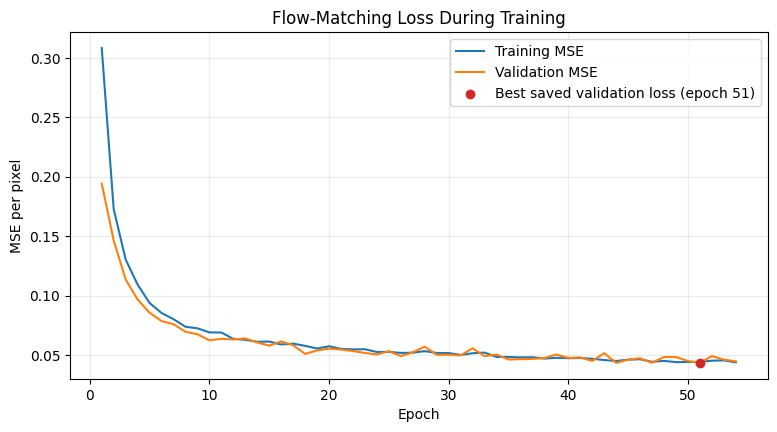

Epochs in checkpoint history: 54


In [9]:
history_payload = best_payload
if LATEST_CHECKPOINT.is_file():
    history_payload = torch.load(LATEST_CHECKPOINT, map_location='cpu', weights_only=False)

train_history = history_payload.get('train_history', [])
val_history = history_payload.get('val_history', [])
if train_history and val_history:
    epochs = np.arange(1, min(len(train_history), len(val_history)) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(epochs, train_history[:len(epochs)], label='Training MSE')
    ax.plot(epochs, val_history[:len(epochs)], label='Validation MSE')
    best_epoch = int(np.argmin(val_history)) + 1
    ax.scatter([best_epoch], [val_history[best_epoch - 1]], color='tab:red', zorder=3,
               label=f'Best saved validation loss (epoch {best_epoch})')
    ax.set(title='Flow-Matching Loss During Training', xlabel='Epoch', ylabel='MSE per pixel')
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
    print(f'Epochs in checkpoint history: {len(epochs)}')
else:
    print('No loss history found in the checkpoint; the objective evaluation below can still run.')

## 2. Flow-Matching Objective on Test Pairs

For each image pair, sample several independent time points $t$. The **zero-velocity baseline MSE** always predicts a velocity of zero and shows whether the model matches the target velocity better than this trivial reference. The metric averages squared error over all pixels and channels.

In [10]:
objective_errors = []
zero_baseline_errors = []
cosine_scores = []
time_error_bins = [dict() for _ in range(TIME_BINS)]
viz_source = None
viz_target = None

with torch.inference_mode():
    for batch_index, (x_a, x_b) in enumerate(test_loader):
        if batch_index >= EVAL_BATCHES:
            break
        x_a = x_a.to(DEVICE)
        x_b = x_b.to(DEVICE)
        if viz_source is None:
            viz_source = x_a[:4].clone()
            viz_target = x_b[:4].clone()

        pair_ids = (batch_index * BATCH_SIZE + torch.arange(x_a.shape[0])).tolist()
        target_velocity = x_b - x_a
        zero_mse = target_velocity.float().square().flatten(1).mean(dim=1)
        for _ in range(TIMES_PER_PAIR):
            t = torch.rand(x_a.shape[0], device=DEVICE)
            t_view = t.view(-1, 1, 1, 1)
            z_t = (1.0 - t_view) * x_a + t_view * x_b
            cond = torch.zeros(x_a.shape[0], dtype=torch.long, device=DEVICE)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_CUDA_AMP):
                pred_velocity = model(z_t, t, cond)

            pred_float = pred_velocity.float()
            target_float = target_velocity.float()
            sample_mse = (pred_float - target_float).square().flatten(1).mean(dim=1)
            cosine = F.cosine_similarity(
                pred_float.flatten(1), target_float.flatten(1), dim=1, eps=1e-8
            )
            objective_errors.append(sample_mse.cpu())
            zero_baseline_errors.append(zero_mse.cpu())
            cosine_scores.append(cosine.cpu())

            bin_ids = torch.clamp((t * TIME_BINS).long(), max=TIME_BINS - 1)
            for bin_id in range(TIME_BINS):
                mask = bin_ids == bin_id
                if mask.any():
                    for pair_id, error in zip(torch.tensor(pair_ids)[mask.cpu()].tolist(), sample_mse[mask].cpu().tolist()):
                        time_error_bins[bin_id].setdefault(pair_id, []).append(error)

objective_errors = torch.cat(objective_errors).numpy()
zero_baseline_errors = torch.cat(zero_baseline_errors).numpy()
cosine_scores = torch.cat(cosine_scores).numpy()
objective_mse = float(objective_errors.mean())
zero_mse = float(zero_baseline_errors.mean())
relative_improvement = 1.0 - objective_mse / zero_mse if zero_mse > 0 else float('nan')

print(f'Test pairs: up to {EVAL_BATCHES * BATCH_SIZE}; random t samples per pair: {TIMES_PER_PAIR}')
print(f'Flow-matching MSE:             {objective_mse:.6f}')
print(f'Zero-velocity baseline MSE:    {zero_mse:.6f}')
print(f'Relative MSE reduction vs zero: {100 * relative_improvement:.1f}%')
print(f'Mean velocity cosine similarity: {cosine_scores.mean():.4f}')
print(f'90th percentile pairwise MSE: {np.quantile(objective_errors, 0.90):.6f}')

Test pairs: up to 512; random t samples per pair: 3
Flow-matching MSE:             0.045898
Zero-velocity baseline MSE:    0.451372
Relative MSE reduction vs zero: 89.8%
Mean velocity cosine similarity: 0.9128
90th percentile pairwise MSE: 0.089860


## 3. Error Distribution and Dependence on $t$

A mean alone can hide difficult pairs. The histogram shows the distribution of pairwise errors; the second plot shows whether the objective is fitted noticeably worse in particular time intervals. Error bars indicate the standard error of the mean within each interval.

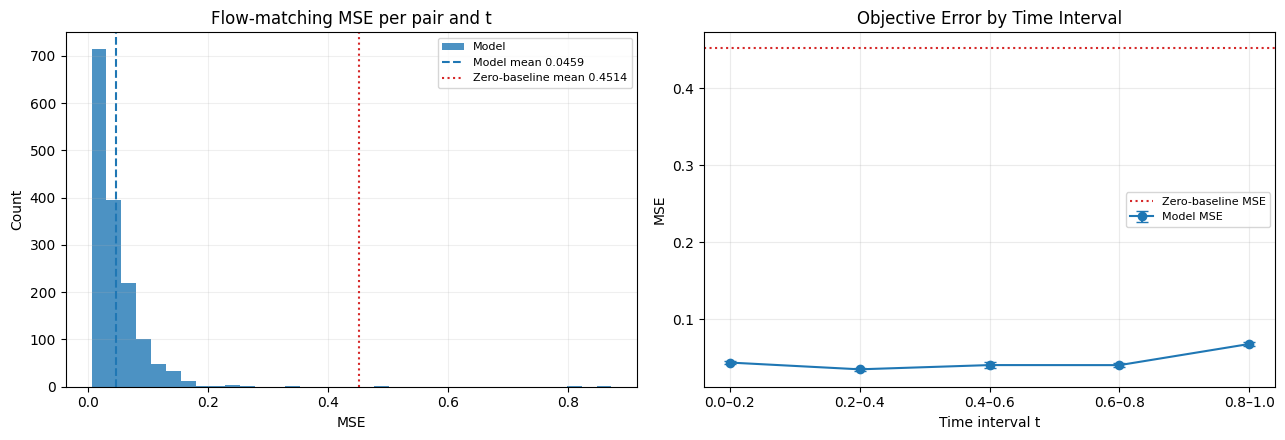

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(objective_errors, bins=35, alpha=0.8, label='Model')
axes[0].axvline(objective_mse, color='tab:blue', linestyle='--', label=f'Model mean {objective_mse:.4f}')
axes[0].axvline(zero_mse, color='tab:red', linestyle=':', label=f'Zero-baseline mean {zero_mse:.4f}')
axes[0].set(title='Flow-matching MSE per pair and t', xlabel='MSE', ylabel='Count')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

bin_means = []
bin_sems = []
bin_labels = []
for bin_index, values in enumerate(time_error_bins):
    if values:
        pair_means = np.asarray([np.mean(pair_errors) for pair_errors in values.values()])
        bin_means.append(float(pair_means.mean()))
        bin_sems.append(float(pair_means.std(ddof=1) / np.sqrt(len(pair_means))) if len(pair_means) > 1 else 0.0)
        bin_labels.append(f'{bin_index / TIME_BINS:.1f}–{(bin_index + 1) / TIME_BINS:.1f}')
axes[1].errorbar(bin_labels, bin_means, yerr=bin_sems, marker='o', capsize=4, label='Model MSE')
axes[1].axhline(zero_mse, color='tab:red', linestyle=':', label='Zero-baseline MSE')
axes[1].set(title='Objective Error by Time Interval', xlabel='Time interval t', ylabel='MSE')
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Training Bridge vs. Learned Flow Trajectory

The first figure shows the exact pixel-linear training bridge $z_t=(1-t)x_a+tx_b$. For unrelated sneaker/boot pairs, intermediate values are expected to look like transparent overlays; the objective does not define a semantic morph. The second figure integrates the learned velocity field from the source. This model is not conditioned on the particular paired target, so the integrated endpoint should be interpreted as a sample from the target-class distribution, not as a reconstruction of the row's $x_b$. These are two different paths and should not be conflated.

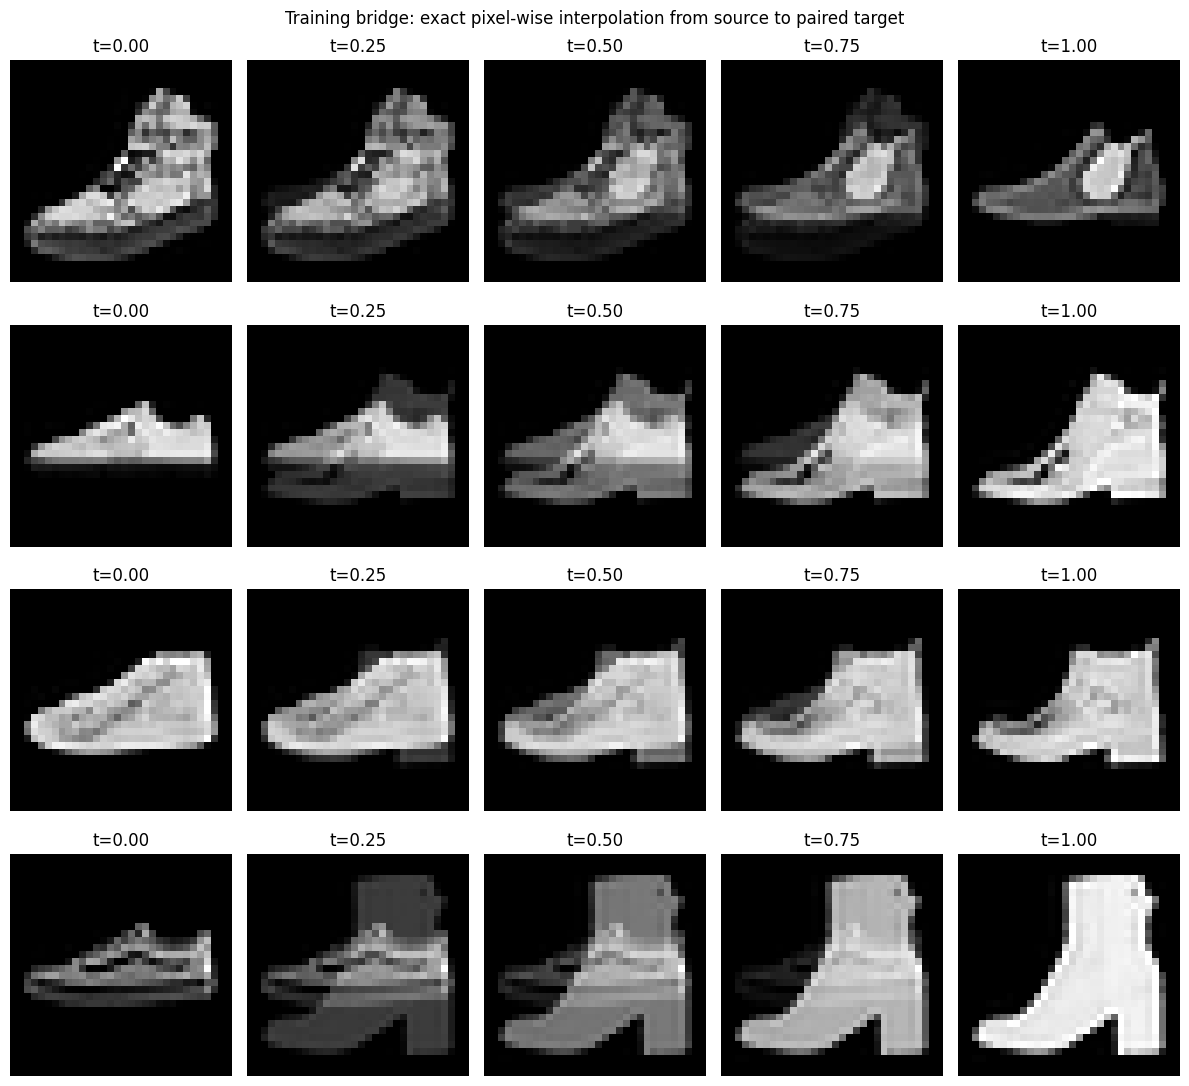

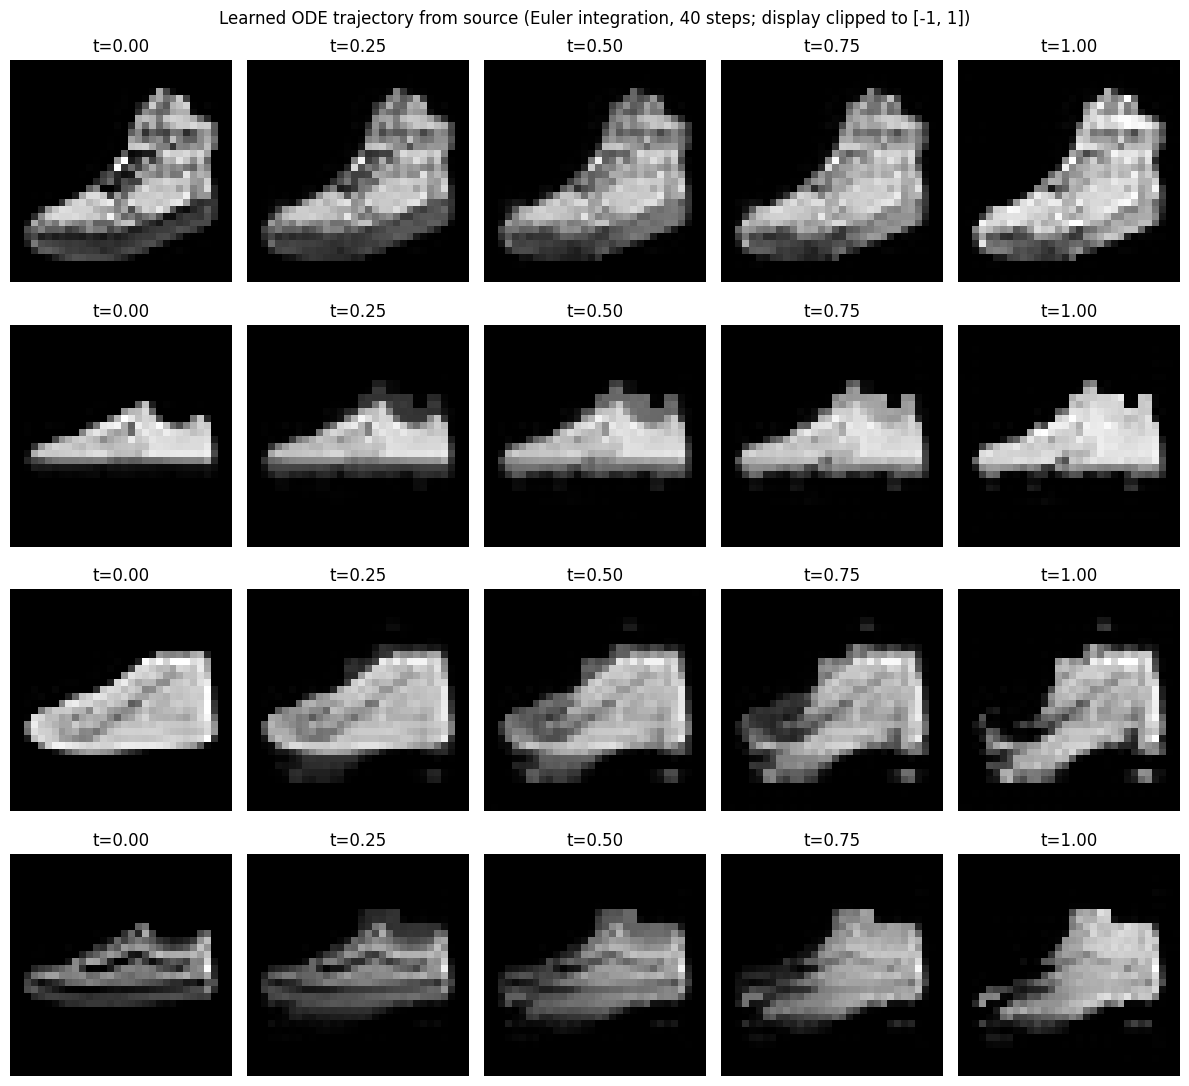

Examples shown: 4; flow integration steps: 40
ODE output range check (values outside [-1, 1] are clipped in the display):
  t=0.00: min=-1.000, max=1.000, outside range=0.0%
  t=0.25: min=-1.038, max=0.933, outside range=22.9%
  t=0.50: min=-1.079, max=0.912, outside range=23.7%
  t=0.75: min=-1.101, max=0.958, outside range=24.0%
  t=1.00: min=-1.143, max=1.183, outside range=27.8%


In [12]:
n_viz = min(4, len(viz_source))
bridge_times = np.linspace(0.0, 1.0, 5)
source = viz_source[:n_viz].to(DEVICE)
target = viz_target[:n_viz].to(DEVICE)

with torch.inference_mode():
    bridge_frames = [
        (1.0 - t_value) * source + t_value * target
        for t_value in bridge_times
    ]
    trajectory_steps = 40
    flow_trajectory = flow_model.sample(source, steps=trajectory_steps)
    snapshot_steps = np.linspace(0, trajectory_steps, len(bridge_times)).round().astype(int)

fig, axes = plt.subplots(n_viz, len(bridge_times), figsize=(12, 2.8 * n_viz), squeeze=False)
for row in range(n_viz):
    for col, (t_value, frame) in enumerate(zip(bridge_times, bridge_frames)):
        image = ((frame[row, 0].detach().cpu() + 1.0) / 2.0).clamp(0.0, 1.0)
        axes[row, col].imshow(image, cmap='gray', vmin=0.0, vmax=1.0)
        axes[row, col].set_title(f't={t_value:.2f}')
        axes[row, col].axis('off')
fig.suptitle('Training bridge: exact pixel-wise interpolation from source to paired target')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(n_viz, len(snapshot_steps), figsize=(12, 2.8 * n_viz), squeeze=False)
for row in range(n_viz):
    for col, step in enumerate(snapshot_steps):
        image = ((flow_trajectory[step][row, 0].detach().cpu() + 1.0) / 2.0).clamp(0.0, 1.0)
        axes[row, col].imshow(image, cmap='gray', vmin=0.0, vmax=1.0)
        axes[row, col].set_title(f't={step / trajectory_steps:.2f}')
        axes[row, col].axis('off')
fig.suptitle(f'Learned ODE trajectory from source (Euler integration, {trajectory_steps} steps; display clipped to [-1, 1])')
plt.tight_layout()
plt.show()

print(f'Examples shown: {n_viz}; flow integration steps: {trajectory_steps}')
print('ODE output range check (values outside [-1, 1] are clipped in the display):')
for step in snapshot_steps:
    frame = flow_trajectory[step]
    outside_range = ((frame < -1.0) | (frame > 1.0)).float().mean().item()
    print(
        f"  t={step / trajectory_steps:.2f}: "
        f"min={frame.min().item():.3f}, max={frame.max().item():.3f}, "
        f"outside range={outside_range:.1%}"
    )

## Interpretation and Limitations

- **Flow-matching MSE:** measures squared velocity error on the sampled test pairs and time points. For checkpoints trained before the split fix, this test split may not be independent of checkpoint selection.
- **Zero-velocity baseline:** a useful reference; a lower model MSE means the model approximates the random target velocity better than predicting zero.
- **MSE by $t$:** can indicate time intervals where the regression target may be harder to fit, but the five broad bins can hide endpoint errors. The Euler sampler queries exactly $t=0$ on its first step, so a low average over $t\in[0,0.2)$ does not guarantee a good initial velocity.
- **Training bridge vs. ODE trajectory:** the bridge is the pixel-wise interpolation used to construct training inputs; the ODE path is generated by integrating the learned field and is not tied to the paired target image. Display values outside the normalized image range are clipped, with the fraction reported above.

Note: These checks do **not** establish that integrated trajectories are realistic, semantically meaningful, or better than other methods. The trajectory examples are qualitative and are not a substitute for distribution-level evaluation.